# PCD Assignment 03: K-Means Clustering + Operasi Morfologi

Nama:
NIM:

Notebook ini bekerja dalam empat tahap:
1. Tiga citra diupload dan dibaca sebagai array RGB.
2. Ketiganya disegmentasi dengan K-Means Clustering.
3. Setiap hasil segmentasi diproses dengan tiga operasi morfologi: opening, closing, dan opening-closing.
4. Hasilnya dievaluasi dengan metrik sederhana (Accuracy, Precision, Recall, Dice, IoU) dan dibandingkan dengan segmentasi sebelum morfologi.

K-Means, operasi morfologi, Otsu (hanya untuk referensi cadangan), dan metrik semuanya ditulis sendiri dengan numpy, tanpa OpenCV, scikit-image, scipy, maupun scikit-learn. PIL hanya membaca file gambar menjadi array, dan matplotlib hanya menampilkan gambar.

In [ ]:
import io

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

## 1. Citra

Tiga citra diupload sekaligus lewat dialog Colab, lalu diurutkan berdasarkan nama file.

In [6]:
uploaded = files.upload()
names = sorted(uploaded.keys())
assert len(names) == 3, f"Harus tepat 3 gambar, yang terupload {len(names)}"

MAX_SIDE = 1000


def resize_nearest(a, new_h, new_w):
    rows = (np.arange(new_h) * a.shape[0] / new_h).astype(int)
    cols = (np.arange(new_w) * a.shape[1] / new_w).astype(int)
    return a[rows][:, cols]


def load_rgb(data):
    rgb = np.array(Image.open(io.BytesIO(data)).convert("RGB"), dtype=np.float64)
    h, w, _ = rgb.shape
    scale = min(1.0, MAX_SIDE / max(h, w))
    if scale < 1.0:
        rgb = resize_nearest(rgb, int(h * scale), int(w * scale))
    return rgb


citra = [load_rgb(uploaded[n]) for n in names]
for n, c in zip(names, citra):
    print(f"{n}: {c.shape[0]}x{c.shape[1]}")

Saving lake2.jpg to lake2.jpg
Saving lake.jpg to lake.jpg
Saving Great_Lakes_pillars.jpg to Great_Lakes_pillars (4).jpg
Great_Lakes_pillars (4).jpg: 784x1000
lake.jpg: 600x900
lake2.jpg: 501x399


## 2. Segmentasi: K-Means Clustering

Setiap piksel dianggap sebagai satu titik dengan tiga fitur (R, G, B). K-Means mengelompokkan titik-titik itu menjadi K cluster. Prosesnya: pusat cluster ditentukan lebih dulu (dengan K-Means++ supaya letaknya tersebar), tiap piksel masuk ke pusat terdekat, lalu pusat dihitung ulang sebagai rata-rata anggotanya. Dua langkah ini berulang sampai pusat hampir tidak bergeser. Seluruh proses dijalankan 5 kali dengan inisialisasi berbeda, dan hasil dengan total jarak terkecil yang dipakai.

K-Means hanya menghasilkan label cluster, belum berupa objek dan latar. Untuk membentuk mask, cluster yang paling banyak muncul di tepi gambar dianggap latar, dan cluster lainnya dianggap objek. Aturan ini sesuai untuk objek yang berada di bagian tengah dengan latar polos di sekelilingnya.

In [7]:
def jarak_ke_pusat(X, pusat):
    return ((X[:, None, :] - pusat[None, :, :]) ** 2).sum(axis=2)


def init_kmeanspp(X, k, rng):
    pusat = [X[rng.integers(len(X))]]
    for _ in range(1, k):
        d2 = jarak_ke_pusat(X, np.array(pusat)).min(axis=1)
        p = d2 / d2.sum() if d2.sum() > 0 else None
        pusat.append(X[rng.choice(len(X), p=p)])
    return np.array(pusat, dtype=np.float64)


def kmeans(X, k, n_init=5, max_iter=100, tol=1e-3, seed=0):
    rng = np.random.default_rng(seed)
    terbaik = None
    for _ in range(n_init):
        pusat = init_kmeanspp(X, k, rng)
        for _ in range(max_iter):
            label = jarak_ke_pusat(X, pusat).argmin(axis=1)
            baru = pusat.copy()
            for j in range(k):
                anggota = X[label == j]
                # cluster kosong dipindah ke titik acak supaya tidak hilang
                baru[j] = anggota.mean(axis=0) if len(anggota) else X[rng.integers(len(X))]
            geser = np.abs(baru - pusat).max()
            pusat = baru
            if geser < tol:
                break
        label = jarak_ke_pusat(X, pusat).argmin(axis=1)
        inertia = np.sum((X - pusat[label]) ** 2)
        if terbaik is None or inertia < terbaik[0]:
            terbaik = (inertia, pusat, label)
    return terbaik[1], terbaik[2]


def segmentasi_kmeans(rgb, k, objek=None):
    h, w, _ = rgb.shape
    pusat, label = kmeans(rgb.reshape(-1, 3), k)
    label_img = label.reshape(h, w)

    if objek is None:
        tepi = np.concatenate([label_img[0], label_img[-1], label_img[:, 0], label_img[:, -1]])
        latar = np.bincount(tepi, minlength=k).argmax()
        objek = [j for j in range(k) if j != latar]

    mask = np.isin(label_img, objek)
    return mask, label_img, pusat, objek

### Jumlah cluster tiap citra

`k` adalah jumlah cluster. K = 2 sudah cukup untuk objek kontras tinggi di latar polos. K = 3 berguna kalau objek punya dua warna dominan, tetapi pada latar polos K ini sering memecah latar menjadi dua tingkat warna, sehingga satu bagian latar ikut terhitung sebagai objek oleh aturan otomatis. Dalam kasus itu `objek` diatur manual. K yang terlalu besar memecah satu objek menjadi banyak potongan.

`objek` berisi nomor cluster yang dianggap objek. Nilai `None` berarti dipilih otomatis dengan aturan tepi di atas. Nomor cluster beserta warna pusatnya dicetak di bawah hasil segmentasi.

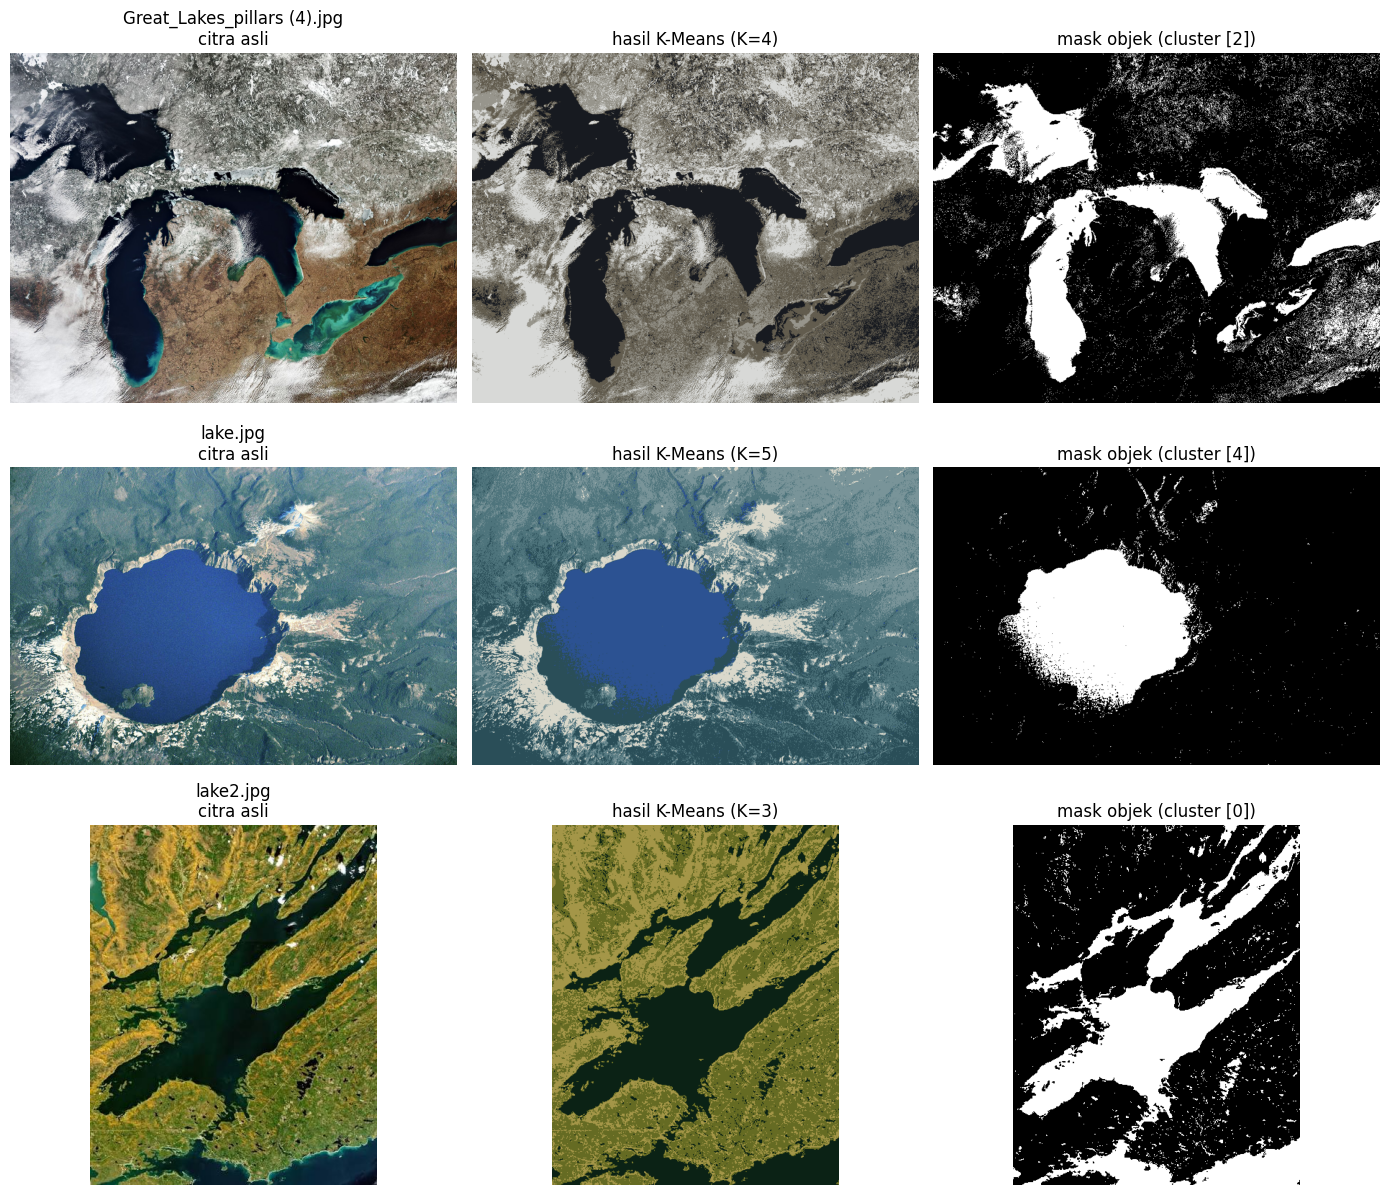

Great_Lakes_pillars (4).jpg
  cluster 0: RGB (99, 93, 78), 30.0% piksel, latar
  cluster 1: RGB (152, 149, 140), 26.4% piksel, latar
  cluster 2: RGB (23, 26, 32), 22.0% piksel, objek
  cluster 3: RGB (217, 217, 216), 21.7% piksel, latar
lake.jpg
  cluster 0: RGB (42, 78, 89), 23.0% piksel, latar
  cluster 1: RGB (218, 216, 203), 8.1% piksel, latar
  cluster 2: RGB (121, 149, 153), 21.9% piksel, latar
  cluster 3: RGB (79, 117, 124), 31.8% piksel, latar
  cluster 4: RGB (45, 82, 146), 15.2% piksel, objek
lake2.jpg
  cluster 0: RGB (12, 35, 22), 28.8% piksel, objek
  cluster 1: RGB (102, 107, 36), 42.6% piksel, latar
  cluster 2: RGB (164, 151, 73), 28.6% piksel, latar


In [18]:
# contoh pengaturan manual citra ke-2: 5 cluster, cluster 2 dianggap objek
PARAMS = [
       {"k": 4, "objek": [2]},   # Great_Lakes_pillars.jpg
       {"k": 5, "objek": [4]},   # lake.jpg
       {"k": 3, "objek": [0]},   # lake2.jpg
]

SE_RADIUS = 2  # radius structuring element disk (piksel)

segmentasi, label_imgs, pusat_all, objek_all = [], [], [], []
for rgb, p in zip(citra, PARAMS):
    mask, label_img, pusat, objek = segmentasi_kmeans(rgb, p["k"], p["objek"])
    segmentasi.append(mask)
    label_imgs.append(label_img)
    pusat_all.append(pusat)
    objek_all.append(objek)

fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for i in range(3):
    axes[i, 0].imshow(citra[i].astype(np.uint8))
    axes[i, 0].set_title(f"{names[i]}\ncitra asli")
    axes[i, 1].imshow(pusat_all[i][label_imgs[i]].astype(np.uint8))
    axes[i, 1].set_title(f"hasil K-Means (K={PARAMS[i]['k']})")
    axes[i, 2].imshow(segmentasi[i], cmap="gray")
    axes[i, 2].set_title(f"mask objek (cluster {objek_all[i]})")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

for i in range(3):
    print(f"{names[i]}")
    for j, c in enumerate(pusat_all[i]):
        tanda = "objek" if j in objek_all[i] else "latar"
        luas = 100 * np.mean(label_imgs[i] == j)
        print(f"  cluster {j}: RGB ({c[0]:.0f}, {c[1]:.0f}, {c[2]:.0f}), {luas:.1f}% piksel, {tanda}")

## 3. Operasi morfologi pada hasil segmentasi

Erosi dan dilasi biner memakai structuring element berbentuk disk. Dari keduanya dibentuk tiga operasi:

- opening: erosi lalu dilasi, menghapus bintik kecil dan sambungan tipis
- closing: dilasi lalu erosi, menutup lubang dan celah kecil
- opening-closing: opening dilanjutkan dengan closing

Pada erosi, tepi gambar di-pad dengan foreground supaya objek yang menyentuh tepi tidak ikut terkikis, sedangkan pada dilasi tepi di-pad dengan background. Disk bersifat simetris, jadi structuring element tidak perlu dipantulkan.

In [19]:
def disk_se(radius):
    y, x = np.ogrid[-radius:radius + 1, -radius:radius + 1]
    return (x * x + y * y) <= radius * radius


def erode(mask, se):
    kh, kw = se.shape
    ph, pw = kh // 2, kw // 2
    h, w = mask.shape
    padded = np.pad(mask, ((ph, ph), (pw, pw)), constant_values=True)
    out = np.ones((h, w), dtype=bool)
    for i in range(kh):
        for j in range(kw):
            if se[i, j]:
                out &= padded[i:i + h, j:j + w]
    return out


def dilate(mask, se):
    kh, kw = se.shape
    ph, pw = kh // 2, kw // 2
    h, w = mask.shape
    padded = np.pad(mask, ((ph, ph), (pw, pw)), constant_values=False)
    out = np.zeros((h, w), dtype=bool)
    for i in range(kh):
        for j in range(kw):
            if se[i, j]:
                out |= padded[i:i + h, j:j + w]
    return out


def opening(mask, se):
    return dilate(erode(mask, se), se)


def closing(mask, se):
    return erode(dilate(mask, se), se)


def opening_closing(mask, se):
    return closing(opening(mask, se), se)

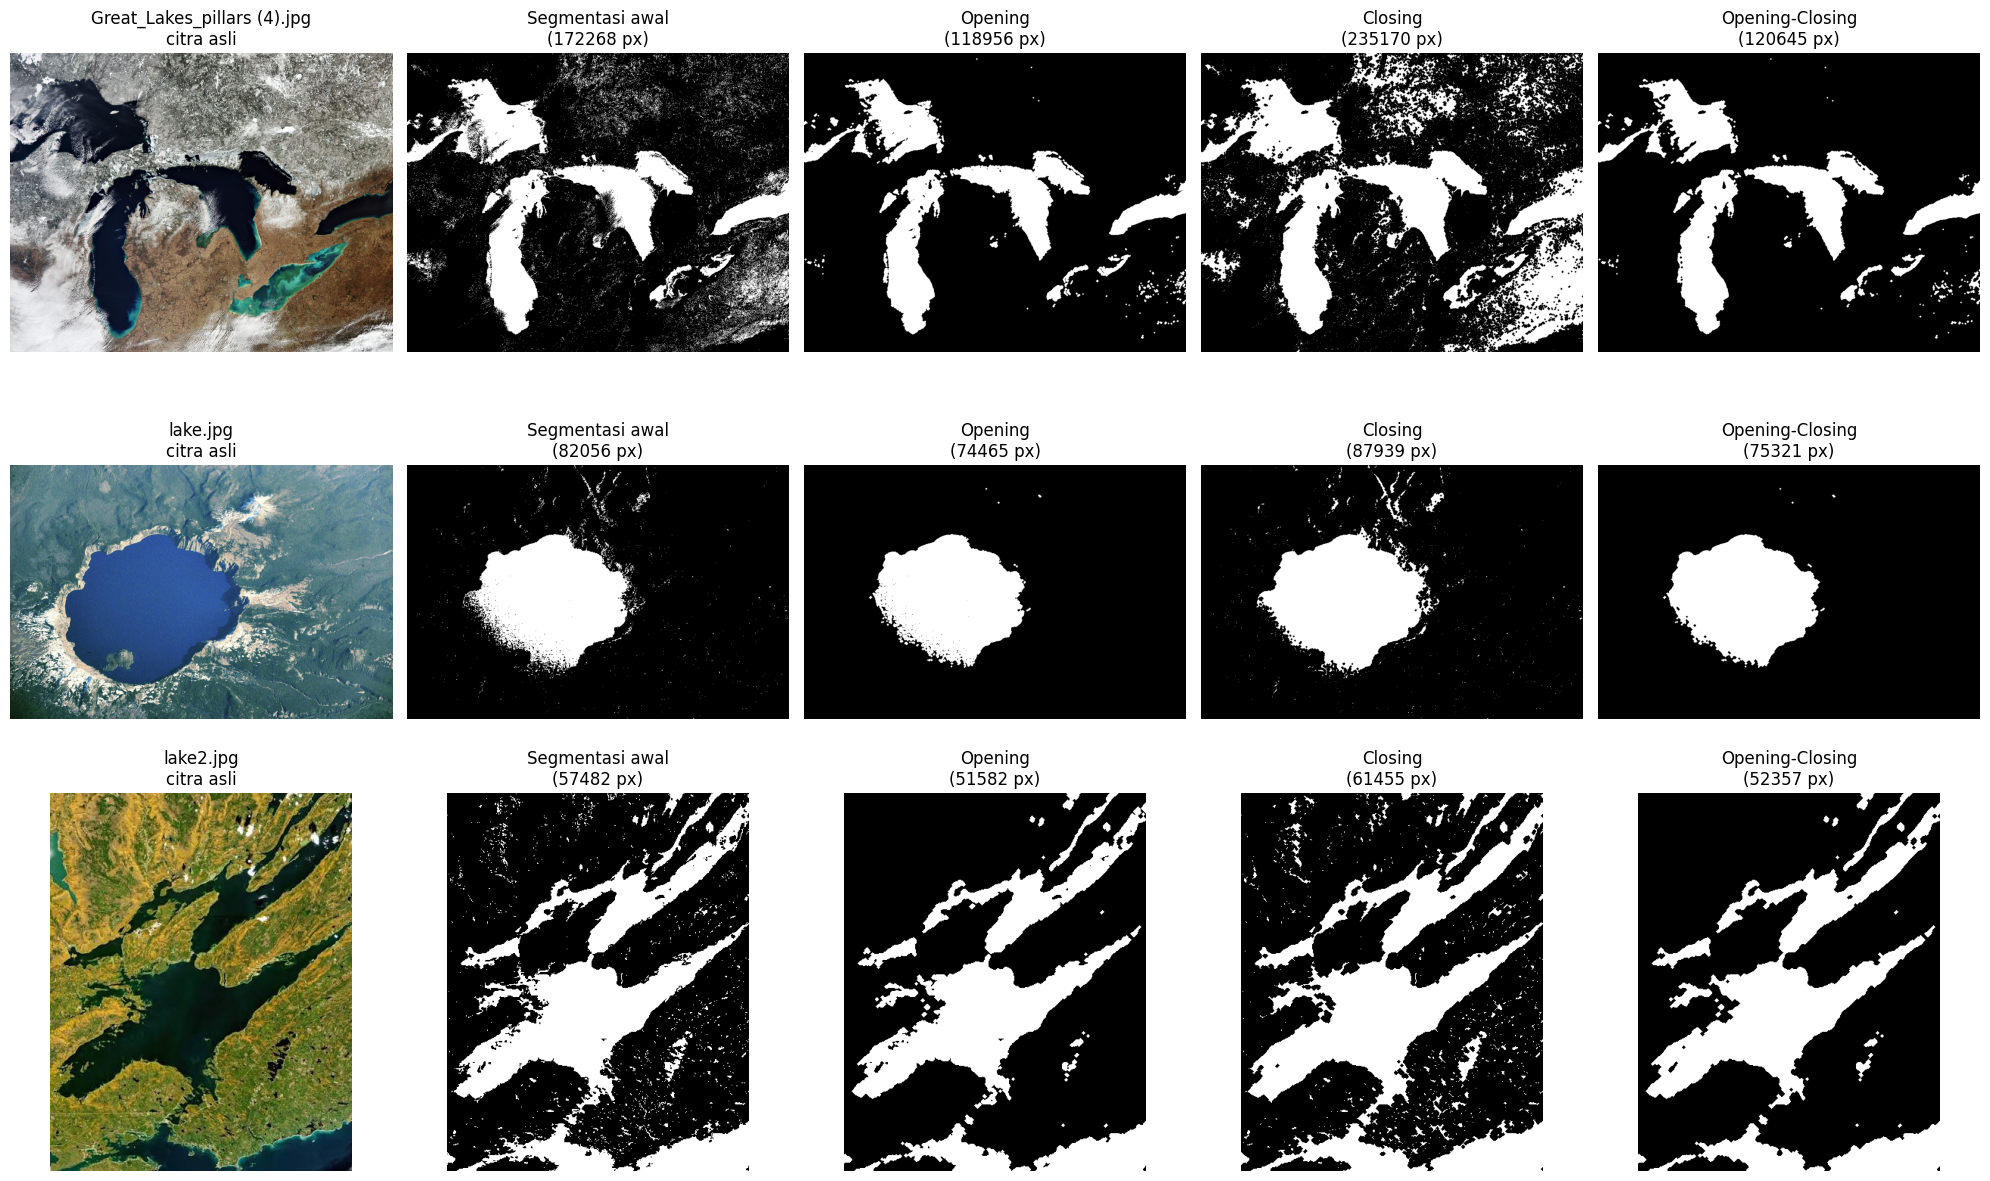

In [20]:
se = disk_se(SE_RADIUS)

varian = ["Segmentasi awal", "Opening", "Closing", "Opening-Closing"]

hasil = []
for seg in segmentasi:
    hasil.append({
        "Segmentasi awal": seg,
        "Opening": opening(seg, se),
        "Closing": closing(seg, se),
        "Opening-Closing": opening_closing(seg, se),
    })

fig, axes = plt.subplots(3, 5, figsize=(20, 12))
for i in range(3):
    axes[i, 0].imshow(citra[i].astype(np.uint8))
    axes[i, 0].set_title(f"{names[i]}\ncitra asli")
    for j, v in enumerate(varian, start=1):
        axes[i, j].imshow(hasil[i][v], cmap="gray")
        axes[i, j].set_title(f"{v}\n({hasil[i][v].sum()} px)")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

In [21]:
   def hitung_komponen(mask):
       h, w = mask.shape
       terlihat = np.zeros((h, w), dtype=bool)
       jumlah, kecil = 0, 0
       for r0 in range(h):
           for c0 in range(w):
               if mask[r0, c0] and not terlihat[r0, c0]:
                   terlihat[r0, c0] = True
                   tumpukan = [(r0, c0)]
                   ukuran = 0
                   while tumpukan:
                       r, c = tumpukan.pop()
                       ukuran += 1
                       for dr in (-1, 0, 1):
                           for dc in (-1, 0, 1):
                               nr, nc = r + dr, c + dc
                               if 0 <= nr < h and 0 <= nc < w and mask[nr, nc] and not terlihat[nr, nc]:
                                   terlihat[nr, nc] = True
                                   tumpukan.append((nr, nc))
                   jumlah += 1
                   if ukuran < 100:
                       kecil += 1
       return jumlah, kecil


   for i in range(3):
       print(names[i])
       awal = int(hasil[i]["Segmentasi awal"].sum())
       for v in varian:
           m = hasil[i][v]
           px = int(m.sum())
           jumlah, kecil = hitung_komponen(m)
           print(f"  {v:<16} {px:>8} px ({100 * (px - awal) / awal:+.1f}%)  komponen: {jumlah}, di antaranya < 100 px: {kecil}")

Great_Lakes_pillars (4).jpg
  Segmentasi awal    172268 px (+0.0%)  komponen: 12589, di antaranya < 100 px: 12553
  Opening            118956 px (-30.9%)  komponen: 140, di antaranya < 100 px: 118
  Closing            235170 px (+36.5%)  komponen: 4163, di antaranya < 100 px: 4103
  Opening-Closing    120645 px (-30.0%)  komponen: 99, di antaranya < 100 px: 77
lake.jpg
  Segmentasi awal     82056 px (+0.0%)  komponen: 1059, di antaranya < 100 px: 1054
  Opening             74465 px (-9.3%)  komponen: 19, di antaranya < 100 px: 18
  Closing             87939 px (+7.2%)  komponen: 610, di antaranya < 100 px: 602
  Opening-Closing     75321 px (-8.2%)  komponen: 11, di antaranya < 100 px: 10
lake2.jpg
  Segmentasi awal     57482 px (+0.0%)  komponen: 1077, di antaranya < 100 px: 1065
  Opening             51582 px (-10.3%)  komponen: 38, di antaranya < 100 px: 24
  Closing             61455 px (+6.9%)  komponen: 692, di antaranya < 100 px: 680
  Opening-Closing     52357 px (-8.9%)  kompo